In [2]:
import os
os.chdir("..")

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from src.data import add_features, clean_data, load_data
from src.preprocessing import build_preprocessor

In [4]:
df = add_features(clean_data(load_data()))
X, y = df.drop(columns="Churn"), df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.2, stratify=y, random_state=42
)

In [5]:
#Arbre non contraint : on provoque volontairement le surapprentissage ---
tree_full = Pipeline([
 ("prep", build_preprocessor(X_train)),
 ("model", DecisionTreeClassifier(random_state=42)),
])
tree_full.fit(X_train, y_train)
print("Train accuracy :", tree_full.score(X_train, y_train)) # ~ 1.00
print("Test accuracy :", tree_full.score(X_test, y_test)) # nettement plus bas
print("Profondeur :", tree_full["model"].get_depth())


Train accuracy : 0.9980475683351083
Test accuracy : 0.7345635202271115
Profondeur : 26


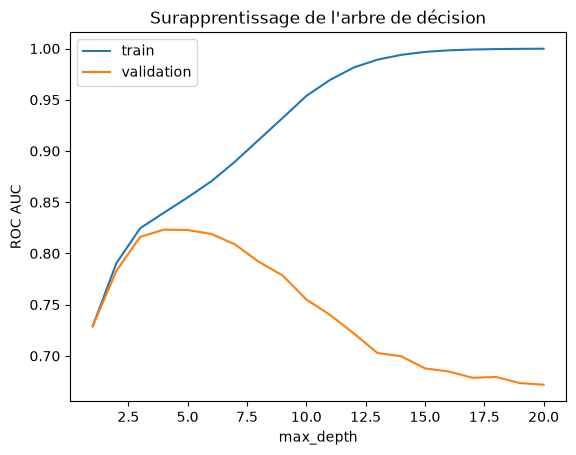

Meilleure profondeur : 4


In [6]:
# Courbe de validation : trouver la bonne max_depth 
depths = np.arange(1, 21)
train_sc, val_sc = validation_curve(
 tree_full, X_train, y_train,
 param_name="model__max_depth", param_range=depths,
 cv=5, scoring="roc_auc",
)
plt.plot(depths, train_sc.mean(axis=1), label="train")
plt.plot(depths, val_sc.mean(axis=1), label="validation")
plt.xlabel("max_depth"); plt.ylabel("ROC AUC"); plt.legend()
plt.title("Surapprentissage de l'arbre de décision")
plt.show()
best_depth = int(depths[val_sc.mean(axis=1).argmax()])
print("Meilleure profondeur :", best_depth)

In [7]:
# Arbre régularisé
tree = Pipeline([
 ("prep", build_preprocessor(X_train)),
 ("model", DecisionTreeClassifier(
 max_depth=best_depth, min_samples_leaf=20,
 class_weight="balanced", random_state=42)),
])
tree.fit(X_train, y_train)
print(classification_report(y_test, tree.predict(X_test)))


              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1035
           1       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



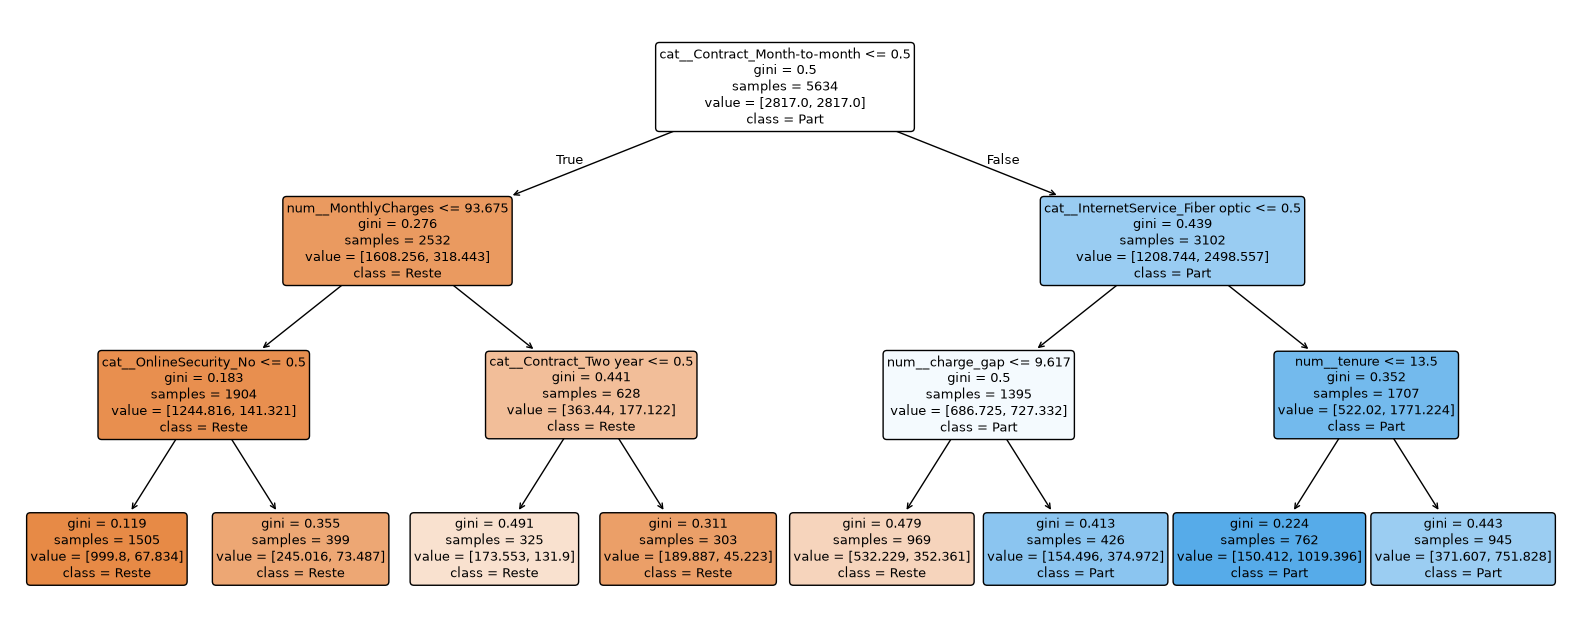

In [8]:
# Visualiser un arbre lisible (profondeur 3)

small = Pipeline([
 ("prep", build_preprocessor(X_train)),
 ("model", DecisionTreeClassifier(max_depth=3, min_samples_leaf=50,
 class_weight="balanced", random_state=42)),
]).fit(X_train, y_train)
plt.figure(figsize=(20, 8))
plot_tree(small["model"],
 feature_names=small["prep"].get_feature_names_out(),
 class_names=["Reste", "Part"], filled=True, rounded=True, fontsize=9)
plt.show()